# Day 1 — Exploration des données et baseline

**Objectif du challenge :** pour chaque visite d'un patient Parkinson, prédire le **vrai score OFF** (`target`, échelle MDS-UPDRS 0–132), c'est-à-dire le score moteur sans l'effet du médicament et sans les biais de mesure.

Ce notebook remplace `archives_py/experiment_day1.py` :
1. charger les données ;
2. les explorer (EDA) ;
3. construire un modèle **dummy** qui sert de score plancher.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")         # masque les avertissements de versions de librairies

# Le notebook est dans notebooks_finaux/ : on se place à la racine du repo pour lire data/,
# et on ajoute notebooks_finaux/ au chemin Python pour importer cv_splits.py et features.py.
if not os.path.exists("data"):
    os.chdir("..")
sys.path.insert(0, os.path.join(os.getcwd(), "notebooks_finaux"))

import numpy as np
import pandas as pd
from sklearn.base import clone            # clone(modèle) = copie du modèle, non entraînée
import skore
from skore import evaluate                # evaluate = entraîne, teste et calcule les métriques

skore.configuration.show_progress = False  # pas de barres de progression dans le notebook

# Les rapports sont déjà sur Skore Hub : PUSH = False évite de les renvoyer en double.
PUSH = False

def push(key, report):
    """Envoie un rapport sur Skore Hub sous le nom `key`, seulement si PUSH vaut True."""
    if not PUSH:
        print(f"(PUSH=False) rapport {key!r} déjà sur le Hub, non renvoyé")
        return
    from skore import Project, login
    cfg = json.load(open(".skore", encoding="utf-8"))          # adresse du Hub, clé API, workspace
    os.environ["SKORE_HUB_URI"], os.environ["SKORE_HUB_API_KEY"] = cfg["hub_url"], cfg["api_key"]
    login(mode="hub")
    Project(name="bobathon-esilv", mode="hub", workspace=cfg["workspace"]).put(key, report)

## 1. Chargement

Chaque ligne est une **visite**. `X_train` contient les mesures, `y_train` le vrai score OFF. On les fusionne sur `Index`.

In [2]:
# Lecture des fichiers de Kaggle
X_train = pd.read_csv("data/X_train.csv")   # mesures des visites du train
y_train = pd.read_csv("data/y_train.csv")   # vrai score OFF (target) de ces visites
X_test = pd.read_csv("data/X_test.csv")     # visites à prédire (sans target)

# On colle la cible aux mesures grâce à la colonne commune Index : une ligne = une visite
visits = X_train.merge(y_train, on="Index")
visits.head()

,Index,patient_id,cohort,sexM,gene,age_at_diagnosis,age,ledd,time_since_intake_on,time_since_intake_off,on,off,target
0,0,IPLP5212,A,0,LRRK2+,48.5,52.1,607.0,1.9,NaN,7.0,NaN,34.7
1,1,IPLP5212,A,0,LRRK2+,48.5,53.0,666.0,1.9,17.6,12.0,44.0,38.1
2,2,IPLP5212,A,0,LRRK2+,48.5,53.9,717.0,1.2,NaN,6.0,NaN,41.6
3,3,IPLP5212,A,0,LRRK2+,48.5,54.8,770.0,1.5,NaN,11.0,NaN,44.9
4,4,IPLP5212,A,0,LRRK2+,48.5,56.9,885.0,0.3,NaN,24.0,NaN,52.0


## 2. Exploration (EDA)

### Visites et patients
Un patient a plusieurs visites. Les patients du test ne sont **pas** dans le train : il faudra en tenir compte pour l'évaluation.

In [3]:
for name, df in [("train", visits), ("test", X_test)]:
    vpp = df.groupby("patient_id").size()   # nombre de visites de chaque patient
    print(f"{name}: {len(df)} visites, {df['patient_id'].nunique()} patients, "
          f"médiane {vpp.median():.0f} visites/patient, max {vpp.max()}")

train: 44590 visites, 5576 patients, médiane 7 visites/patient, max 12
test: 11013 visites, 1395 patients, médiane 7 visites/patient, max 12


### Valeurs manquantes
L'examen OFF est désagréable, il est donc souvent sauté. Les délais de prise du médicament manquent aussi souvent.

In [4]:
# isna().mean() = part de valeurs manquantes de chaque colonne
print(visits.isna().mean().sort_values(ascending=False).round(3).head(6))

print("\nsans off      :", round(visits["off"].isna().mean(), 3))
print("sans on       :", round(visits["on"].isna().mean(), 3))
# & = les deux conditions à la fois : visites sans on ET sans off
print("ni on ni off  :", (visits["on"].isna() & visits["off"].isna()).sum())

time_since_intake_off    0.788
time_since_intake_on     0.464
off                      0.424
ledd                     0.366
gene                     0.324
on                       0.296
dtype: float64

sans off      : 0.424
sans on       : 0.296
ni on ni off  : 0


### Distribution de la cible

count    44590.00
mean        37.47
std         16.50
min          0.00
25%         25.60
50%         37.30
75%         49.30
max        109.50
Name: target, dtype: float64
skewness : 0.05


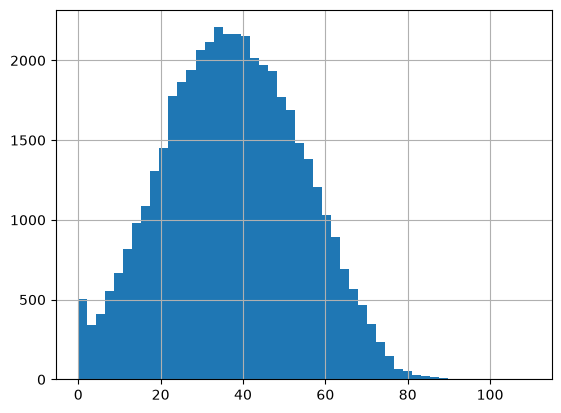

In [5]:
print(visits["target"].describe().round(2))              # min, max, moyenne, quartiles
print("skewness :", round(visits["target"].skew(), 2))   # 0 = distribution symétrique
visits["target"].hist(bins=50);

### Colonnes liées à la cible
On ajoute la durée de la maladie (`age - age_at_diagnosis`).

In [6]:
# Variable temporaire : durée de la maladie en années
visits["time_since_diagnosis"] = visits["age"] - visits["age_at_diagnosis"]

# Corrélation de chaque colonne numérique avec la cible (1 = lien parfait, 0 = aucun lien)
print(visits.select_dtypes("number").drop(columns="Index").corr()["target"].sort_values(ascending=False).round(3))

# Si off était une copie de target, cette erreur serait proche de 0
print("\nRMSE entre off mesuré et target :", round(((visits["off"] - visits["target"]) ** 2).mean() ** 0.5, 2))

visits = visits.drop(columns="time_since_diagnosis")   # retour au tableau d'origine

target                   1.000
off                      0.886
on                       0.688
time_since_diagnosis     0.542
age                      0.310
ledd                     0.298
age_at_diagnosis         0.133
time_since_intake_off    0.008
time_since_intake_on     0.000
sexM                    -0.001
Name: target, dtype: float64

RMSE entre off mesuré et target : 9.99


### `ledd` manquant selon la cohorte

In [7]:
# Pour chaque cohorte, part des visites où ledd (dose de médicament) manque
visits.groupby("cohort")["ledd"].apply(lambda s: s.isna().mean()).round(3)

cohort
A    0.359
B    0.426
Name: ledd, dtype: float64

## 3. Baseline : le modèle dummy

Le dummy prédit **toujours la moyenne** de `target`. Il ne sert pas à bien prédire, mais à donner un **score plancher** : tout vrai modèle doit faire mieux.

`skore.evaluate` découpe les données (20 % gardés pour le test) et calcule les métriques. La métrique de la compétition est le **RMSE** (plus bas = meilleur).

In [8]:
from sklearn.dummy import DummyRegressor

# Les 8 colonnes numériques proposées par le guide (les identifiants et les textes sont exclus)
feature_cols = ["sexM", "age_at_diagnosis", "age", "ledd",
                "time_since_intake_on", "time_since_intake_off", "on", "off"]
X = visits[feature_cols]
y = visits["target"]

dummy = DummyRegressor(strategy="mean")   # prédit toujours la moyenne de y
# evaluate découpe les visites au hasard (80 % train, 20 % test), entraîne et calcule les métriques
report = evaluate(dummy, X, y)
print(f"RMSE dummy : {report.metrics.rmse():.3f}")
print(f"Std target : {y.std():.3f}")
push("01_dummy", report)

RMSE dummy : 16.478
Std target : 16.500
(PUSH=False) rapport '01_dummy' déjà sur le Hub, non renvoyé


### Fichier de soumission Kaggle
On réentraîne sur tout le train, on prédit le test, et on écrit `submissions/01_dummy.csv` (colonnes `Index,target`).

In [9]:
from pathlib import Path

final = clone(dummy).fit(X, y)                  # entraîné sur TOUTES les visites du train
submission = X_test[["Index"]].copy()           # format Kaggle : colonnes Index, target
submission["target"] = final.predict(X_test[feature_cols])
Path("submissions").mkdir(exist_ok=True)
submission.to_csv("submissions/01_dummy.csv", index=False)
submission.shape                                # 11 013 lignes attendues

(11013, 2)

---
## Questions du workbook

### Section 2 — EDA
1. **Visites et patients.** Train : 44 590 visites, 5 576 patients. Test : 11 013 visites, 1 395 patients. Environ 7 visites par patient en médiane, 12 au maximum.
2. **Valeurs manquantes.** Les plus vides : `time_since_intake_off` (79 %), `time_since_intake_on` (46 %), `off` (42 %). 30 % des visites n'ont pas de `on`. Aucune visite n'a ni `on` ni `off`.
3. **Distribution de `target`.** De 0 à 109,5 (moyenne 37,5, écart-type 16,5), jamais près de 132. Presque symétrique (skewness ≈ 0,05).
4. **Colonnes liées à `target`.** `off` est la plus corrélée (0,89), puis `on` (0,69) et la durée de la maladie (0,54). `off` n'est pas une copie : il s'écarte de `target` d'environ 10 points.
5. **`ledd` manquant.** Plus fréquent en cohorte B (43 %) qu'en cohorte A (36 %) : ce n'est pas au hasard, ça dépend du protocole de la cohorte.
6. **Colonnes à ne pas donner au modèle.** `Index` et `patient_id` (identifiants : le modèle les mémoriserait) et `target` (c'est la réponse).

### Section 3 — Dummy
1. **RMSE du dummy.** 16,48, presque égal à l'écart-type de `target` (16,50) : prédire toujours la moyenne donne une erreur égale à l'écart-type.
2. **Graphe prédit vs réel.** Une ligne horizontale, puisque la prédiction est la même pour tous. Un modèle parfait aurait ses points sur la diagonale y = x.
3. **Score à battre : 16,48.** Un gain n'est réel que s'il dépasse la variation entre folds (≈ 0,3 pour le dummy en GroupKFold).